In [1]:
import matplotlib.pyplot as plt
import numpy as np
from typing import Optional
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
import tqdm
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
#print('Current cuda device: ',torch.cuda.get_device_name(0))

In [2]:
!pip install gstools
import gstools as gs

In [3]:
# Codes for the forward tomography problem
class tomography(nn.Module):

    def __init__(self, zs, ze, x, z):
      # rays start at (x[0], zs[i]) and end at (x[-1], ze[j])

        super().__init__()

        self.zs = zs
        self.ze = ze
        self.z  = z
        self.x  = x
        self.A = self.get_tomo_matrix(zs, ze, x, z)


    def get_ray(self, zs, ze, x, z):

        n = x.numel() #64
        X, Z = torch.meshgrid(x, z)


        s = (ze-zs)/(x[-1]-x[0])
        p = s*x + zs

        # Approximate the delta function over the path
        sigma = (x[1]-x[0])*2
        ray = torch.exp(-(X-x.unsqueeze(1))**2/sigma -(Z-p.unsqueeze(1))**2/sigma)
        ray[ray<0.1] = 0
        return ray

    def get_tomo_matrix(self, zs, ze, x, z):

        n = zs.numel() #65*65=4225

        A = torch.zeros(0, x.numel()*z.numel())
        A = A.to_sparse()
        nrays = tqdm.trange(n)

        for i in nrays:
            ray = self.get_ray(zs[i], ze[i], x, z)
            ray = ray.reshape(1, -1)
            ray = ray.to_sparse()
            A = torch.cat((A,ray),dim=0)
            nrays.set_description('Percent computed: {:2f}'.format(100*i/n))

        return A.to(device)

    def forward(self, u):
      return self.A@u.flatten().to(device)

    def adjoint(self, b):
      return self.A.t()@b.flatten().to(device)


In [4]:
x = torch.linspace(0, 127, 128)
z = torch.linspace(0, 127, 128)

t = torch.linspace(0, 127, 33)
zs, ze = torch.meshgrid(t, t)
zs = zs.flatten()
ze = ze.flatten()

tomo = tomography(zs, ze, x, z).to(device)

/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Percent computed: 99.908173: 100%|██████████| 1089/1089 [00:08<00:00, 123.36it/s]


In [5]:
x = np.arange(128)
z = np.arange(128)

model = gs.Gaussian(dim=2, var=0.9, len_scale=[9, 5], anis=0.9, angles=np.pi/8)
srf = gs.SRF(model, mean=0, seed = 100)

srf.structured([x,z])
u_noise = srf.field


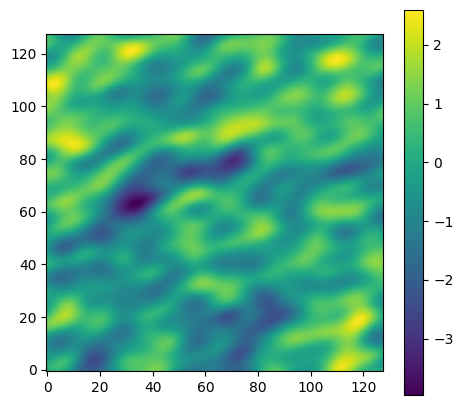

In [6]:
plt.figure(figsize=(25, 5))
plt.subplot(1,4,1)
plt.imshow(u_noise.reshape(128, 128).transpose(), origin = 'lower')
plt.axis('image')
plt.colorbar()

In [7]:
utrue = np.ones([128, 128])
a = 20
center_l_i = 70
center_l_j = 64
center_r_i = 90
center_r_j = 94
for j in range(128):
  for i in range(128):
    r1 = ((i - center_l_i)**2 + (j-center_l_j)**2)**0.5
    r2 = ((i - center_r_i)**2 + (j-center_r_j)**2)**0.5
    if r1+r2<=2*a:
      utrue[i,j] = 8
center_l_i = 25
center_l_j = 74
center_r_i = 45
center_r_j = 44
for j in range(128):
  for i in range(128):
    r1 = ((i - center_l_i)**2 + (j-center_l_j)**2)**0.5
    r2 = ((i - center_r_i)**2 + (j-center_r_j)**2)**0.5
    if r1+r2<=2*a:
      utrue[i,j] = 8
utrue += u_noise
u = torch.tensor(utrue, dtype=torch.float32).to(device)
u[u < 0.3] = 0.3
utrue = u.clone().to(device)

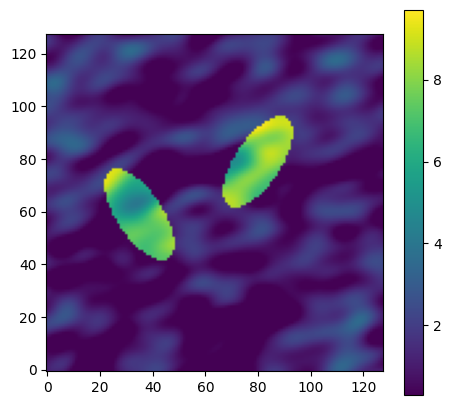

In [8]:
plt.figure(figsize=(25, 5))
plt.subplot(1,4,1)
plt.imshow(utrue.detach().cpu().reshape(128, 128).t(), origin = 'lower')
plt.axis('image')
plt.colorbar()

We can now use the forward model and the simulated model to generate some data we can try to invert

In [9]:
d = tomo(u).to(device)
# Add noise to the data
torch.manual_seed(0)
noise = torch.randn_like(d)
sig   = 20
dn = (d + sig*noise).to(device)

SNR = (dn-d).norm()/dn.norm()
print('Noise level = ', (SNR).item())

Noise level =  0.03453985974192619


In [10]:
class NFTOMO(nn.Module):
    def __init__(self):
         super(NFTOMO, self).__init__()
         self.b1 = nn.Sequential(nn.Linear(2,256), nn.LeakyReLU(inplace = True, negative_slope=0.2))
         self.b2 = nn.Sequential(nn.Linear(256,256), nn.LeakyReLU(inplace = True, negative_slope=0.2))
         self.b3 = nn.Sequential(nn.Linear(256,256), nn.LeakyReLU(inplace = True, negative_slope=0.2))
         self.b4 = nn.Sequential(nn.Linear(256,256), nn.LeakyReLU(inplace = True, negative_slope=0.2))
         self.b5 = nn.Sequential(nn.Linear(256,256), nn.LeakyReLU(inplace = True, negative_slope=0.2))
         self.b6 = nn.Sequential(nn.Linear(256,128), nn.LeakyReLU(inplace = True, negative_slope=0.2))
         self.b7 = nn.Sequential(nn.Linear(128,1), nn.Tanh())

    def forward(self, x):
        x1 = self.b1(x)

        x2 = self.b2(x1)

        x3 = self.b3(x2)

        x4 = self.b4(x3)

        x5 = self.b5(x4)

        x6 = self.b6(x5)

        x7 = self.b7(x6)


        return torch.mul(x7,10)

In [11]:
torch.manual_seed(0)
np.random.seed(0)
_model = NFTOMO().to(device)

In [12]:
x1 = np.linspace(-1,1,128)
x2 = np.linspace(-1,1,128)
input_list = []
for i in x1:
  for k in x2:
    input_list.append([i,k])
input_ = torch.tensor(input_list, dtype=torch.float32).to(device)

In [13]:
output = _model(input_)
# output = _model(input_)

Text(0.5, 1.0, 'inital NF output (Gaussion encoding scale .5)')

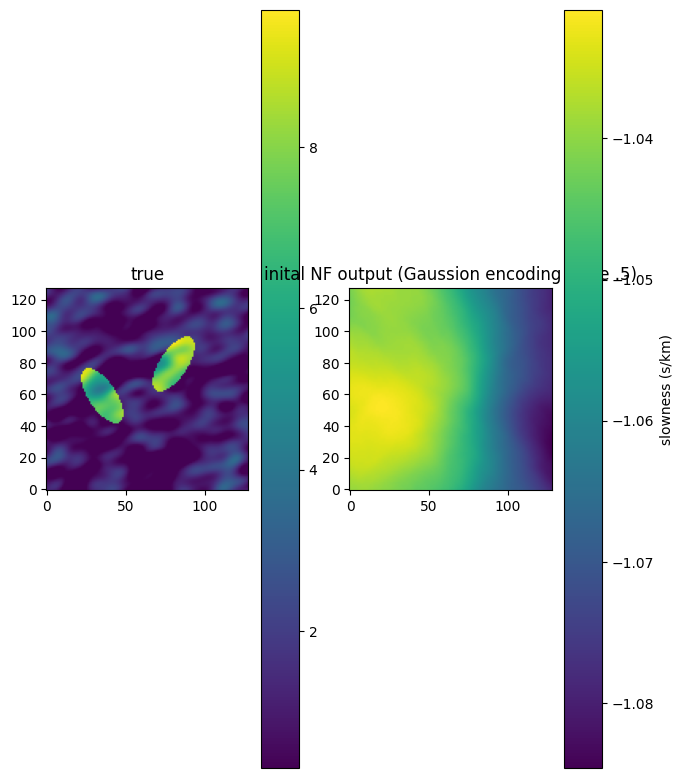

In [14]:
plt.figure(figsize=(15, 15))
plt.subplot(1,4,1)
plt.imshow(utrue.detach().cpu().reshape(128, 128).t(),origin = 'lower')
plt.axis('image')
plt.colorbar()
plt.title('true')
plt.subplot(1,4,2)
plt.imshow(output.detach().cpu().reshape(128, 128).t(), origin = 'lower')
plt.axis('image')
cbar = plt.colorbar()
cbar.set_label('slowness (s/km)')
plt.title('inital NF output (Gaussion encoding scale .5)')

In [15]:
total_params = sum(p.numel() for p in _model.parameters())
print(f"Number of parameters: {total_params}")

Number of parameters: 296961


In [16]:
import torch.optim as optim
lr_ = 1e-3
optimizer = optim.Adam(_model.parameters(), lr=lr_)

In [17]:
def total_loss(output, Jtvec):
      """
          Note beta here differs from the beta in the convential EM inversion where beta typically starts with a value greater than 1 (e.x. 10), and then cooling down with a fixed rate.
          beta: [0,1]
          total_loss = (1-beta)*theta_phi + beta*theta_m
      """
      return (1/(output.size(dim=0)))*(Jtvec.t()@output)

In [18]:
%matplotlib inline
from IPython import display

In [19]:
import pickle

In [20]:
input_.shape

torch.Size([16384, 2])

In [21]:
out_ = tomo.A@(output.detach())
print(out_.shape)

torch.Size([1089, 1])


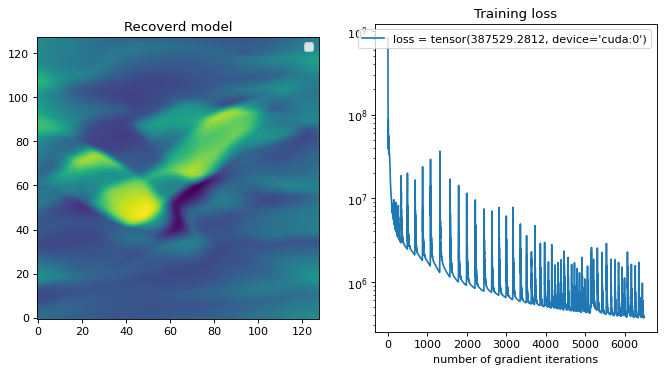

In [22]:

fig = plt.figure(figsize=(10, 5), dpi= 80, facecolor='w', edgecolor='k')
axes = fig.subplots(1,2)
losses = []

for epoch in range(6500): #4500
    output = _model(input_)
    out_ = tomo.A@(output.detach())
    Jtvec = 2*tomo.A.t()@(out_-dn.unsqueeze(-1))
    loss = total_loss(output, Jtvec)
    optimizer.zero_grad()
    loss.backward()
    diff_ = ((out_-dn.unsqueeze(-1)).norm())**2
    losses.append(diff_.item())
    optimizer.step()
    if epoch%10 == 0:
      for ax in axes:
        ax.cla()
      axes[0].imshow(output.detach().cpu().reshape(128, 128).t(), origin = 'lower')
      axes[0].legend()
      axes[0].set_title('Recoverd model')
      axes[1].plot(losses, label='loss = ' + str(diff_))
      axes[1].set_yscale('log')
      axes[1].set_title('Training loss')
      axes[1].set_xlabel('number of gradient iterations')
      axes[1].legend()
      # print("The residual in the ", epoch, "is", ((out_-dn.unsqueeze(-1)).norm())**2)
      display.clear_output(wait=True)
      display.display(plt.gcf())
    if epoch%500 == 0:
      pkl_ = '7_layers_RELU_hete_no_encording'+'_'+str(epoch)
      pkl_name = pkl_+'.pkl'
      f = open(pkl_name, 'wb')
      pickle.dump(output, f)
      f.close()
plt.close('all')

In [23]:
output = _model(input_)

Text(0.5, 1.0, 'Recovered')

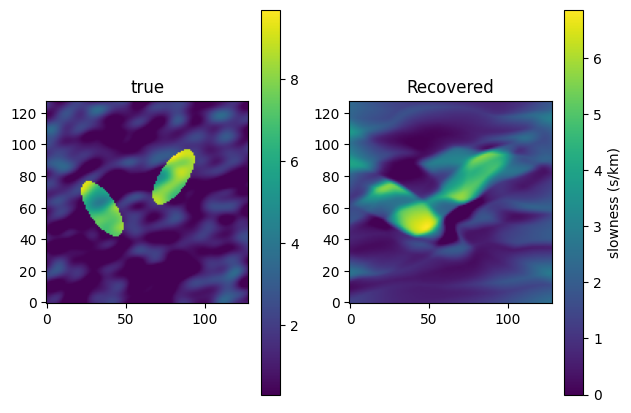

In [24]:

plt.figure(figsize=(15,5))
plt.subplot(1,4,1)
plt.imshow(utrue.detach().cpu().reshape(128, 128).t(), origin = 'lower')
plt.axis('image')
plt.colorbar()
plt.title('true')
plt.subplot(1,4,2)
plt.imshow(output.detach().cpu().reshape(128, 128).t(), origin = 'lower', vmin = 0)
plt.axis('image')
cbar = plt.colorbar()
cbar.set_label('slowness (s/km)')
plt.title('Recovered')

In [25]:
import pickle
r_ = open('/content/7_layers_256_RELU_hete_no_encording_6500.pkl', 'wb')
pickle.dump(output, r_)
r_.close()

In [26]:
import pickle
r_ = open('/content/7_layers_256_RELU_hete_no_encording_6500_loss_list.pkl', 'wb')
pickle.dump(losses, r_)
r_.close()

In [27]:
torch.save(_model, '7_layers_256_RELU_hete_no_encording.pt')

In [28]:
_model = torch.load('7_layers_256_RELU_hete_no_encording.pt', weights_only = False)

In [29]:
ini_weight = [p.data for p in _model.parameters()]

# Calculate the consine similarity of the two directions
def nplist_to_tensor(nplist):
    """ Concatenate a list of numpy vectors into one tensor.
    """
    v = []
    for d in nplist:
        w = torch.tensor(d*np.float64(1.0))
        # Ignoreing the scalar values (w.dim() = 0).
        if w.dim() > 1:
            v.append(w.view(w.numel()))
        elif w.dim() == 1:
            v.append(w)
    return torch.cat(v)

#define loss
def criterion(network, tomo, dn, input):
    """
    network: the model with the shifted weight loaded
    muon_counts_simulator, simpeg_data_container, W: defined based on the survey geometry and field data
    input: input_z (for CNN)
    """
    output = network(input)
    m = output.detach().cpu().flatten().numpy()
    out_ = tomo.A@(output.detach())
    diff_ = 0.5*((out_-dn.unsqueeze(-1)).norm())**2
    return diff_

#define the steps on the two directions
d_1_coordinates= np.linspace(-2.5, 2.5, 101)
d_2_coordinates= np.linspace(-2.5, 2.5, 101)

In [30]:
from time import time

/tmp/ipykernel_3960/2842418370.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  w = torch.tensor(d*np.float64(1.0))


tensor(7.0213e-06, device='cuda:0')
83.82854986190796


/tmp/ipykernel_3960/2842418370.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  w = torch.tensor(d*np.float64(1.0))


tensor(-7.0389e-06, device='cuda:0')
84.21860480308533


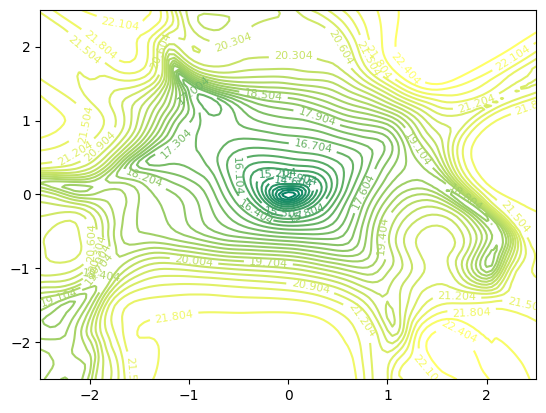

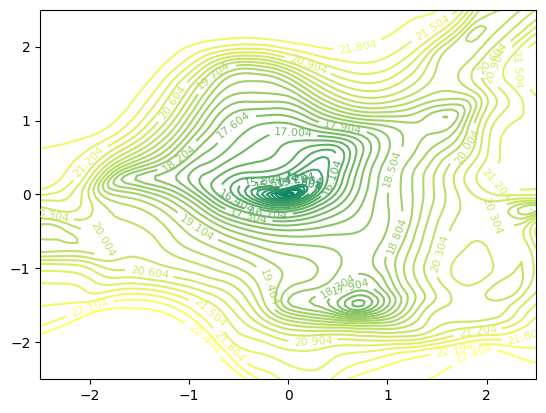

In [31]:
x_1, x_2 = np.meshgrid(d_1_coordinates, d_2_coordinates)


#define the weights (change weights along directions with a step size)
def set_weights(ind_1, ind_2, net, x_1, x_2, d_1, d_2, ini_weight):
    """
    Change weights of the ML model along directions with a step size.
    """
    # d_x_1 = x_1[ind_1][ind_2]* d_1
    # d_x_2 = x_2[ind_1][ind_2]* d_2
    changes = [d1*x_1[ind_1][ind_2] + d2*x_2[ind_1][ind_2] for (d1, d2) in zip(d_1, d_2)]
    for (p, w, d) in zip(net.parameters(), ini_weight, changes):
        p.data = w + torch.Tensor(d).type(type(w)).to(device)

#loss map generation starts!
# direction_seed_list = [100, 2949]
direction_seed_list = [10, 100]
for i in range(len(direction_seed_list)):
    seed_number = int(direction_seed_list[i])
    torch.manual_seed(seed_number)
    np.random.seed(seed_number)
    d_1=[torch.randn(w.size()).to(device).flatten() for w in ini_weight]
    d_2_=[torch.randn(w.size()).to(device).flatten() for w in ini_weight]

    d_2 = []
    for _d_1, _d_2 in zip(d_1, d_2_):
        d_2.append(_d_2 - (torch.dot(_d_1,_d_2)/torch.dot(_d_1,_d_1))*_d_1)

    # Nomalizing the directions using 'filter' node
    for d, w in zip(d_1, ini_weight):
        d.mul_(w.norm()/(d.norm() + 1e-10))
    for d, w in zip(d_2, ini_weight):
        d.mul_(w.norm()/(d.norm() + 1e-10))

    # Calculate the consine similarity of the two directions
    vec1 = nplist_to_tensor(d_1)
    vec2 = nplist_to_tensor(d_2)
    cos_similarity = torch.dot(vec1, vec2)/(vec1.norm()*vec2.norm()).item()
    print(cos_similarity)

    for i in range(len(d_1)):
        d_1[i] = d_1[i].reshape(ini_weight[i].size())
        d_2[i] = d_2[i].reshape(ini_weight[i].size())

    loss_mesh = np.ones(x_1.shape)
    start = time()
    for ind_1 in range(101):
        for ind_2 in range(101):
            set_weights(ind_1, ind_2, _model, x_1, x_2, d_1, d_2, ini_weight)
            _model.eval()
            with torch.no_grad():
                loss_ = criterion(_model, tomo, dn, input_)
                loss_mesh[ind_1][ind_2] = loss_
    end = time()
    print(end-start)
    import pickle
    pkl_name = '/vis_NN_'+str(seed_number)+'_orthogonal.pkl'
    f = open(pkl_name, 'wb')
    pickle.dump(d_1, f)
    pickle.dump(d_2,f)
    pickle.dump(loss_mesh,f)
    pickle.dump(cos_similarity,f)
    f.close()

    fig = plt.figure()
    CS = plt.contour(x_1,x_2, np.log(loss_mesh), cmap='summer', levels=np.arange(min(np.log(loss_mesh.flatten())), max(np.log(loss_mesh.flatten())), .3))
    plt.clabel(CS, inline=1, fontsize=8)
    fig.savefig('/NN_'+str(seed_number)+ '_vis_orthogonal.pdf', dpi=300,
            bbox_inches='tight', format='pdf')

In [32]:
import pickle
r_ = open('/content/7_layers_256_RELU_hete_no_encording_6500_loss_mesh_orthogonal.pkl', 'wb')
pickle.dump(x1, r_)
pickle.dump(x2, r_)
pickle.dump(loss_mesh, r_)
r_.close()